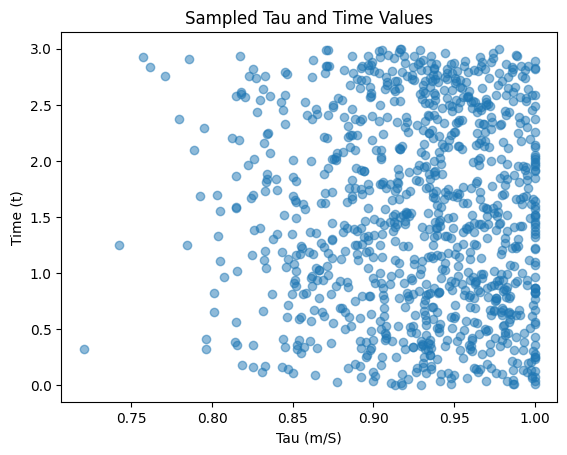

In [ ]:
import time
import wandb
import pickle
import numpy as np
import tensorflow as tf
from math import pi, exp
from scipy.stats import norm
import matplotlib.pyplot as plt

n_dim = 1

#Define global variables
r = 0.01
T = 3
K = 10
sigma = 0.05
DTYPE = 'float32'

#Fix seeds
random_seed = 2
np.random.seed(random_seed)
tf.random.set_seed(random_seed)



# Sampler function for tau and time
class Sampler_IBC():
    def __init__(self, lb, ub, cond=None, N_points=100,
                 method='uniform', grid=None, split=False, DTYPE=DTYPE,
                 batch_size=100, time_steps=50):
        self.lb = lb          # Lower bound
        self.ub = ub          # Upper bound
        self.cond = cond      # Condition for sampling
        self.DTYPE = DTYPE    # Data type for numerical precision
        self.batch_size = batch_size  # Number of paths in a batch
        self.time_steps = time_steps  # Number of time steps for path generation
        self.sample(N_points, method, grid, split)

    def generate_paths(self, N_points):
        S0 = np.random.uniform(self.lb[0], self.ub[0], size=(N_points, 1)).astype(self.DTYPE)  # Initial asset prices
        dt = T / self.time_steps  # Time step size
        paths = [S0]

        # Simulate paths
        for _ in range(1, self.time_steps):
            dW = np.random.normal(loc=0.0, scale=np.sqrt(dt), size=(N_points, 1)).astype(self.DTYPE)
            St = paths[-1] * np.exp((r - 0.5 * sigma**2) * dt + sigma * dW)
            paths.append(St)

        # Concatenate to form path matrix
        paths = np.hstack(paths)  # Shape: (N_points, time_steps)
        return paths

    def calculate_tau(self, paths):
        """
        Calculate tau = m / S for each path.
        """
        S_final = paths[:, -1]  # Final asset price at maturity
        m_values = np.min(paths, axis=1)  # Minimum asset price along each path
        tau_values = m_values / S_final  # Calculate tau
        return tau_values

    def sample(self, N_points, method, grid, split):
        """
        Sample values for tau and time.
        """
        # Step 1: Generate paths
        paths = self.generate_paths(N_points)

        # Step 2: Calculate tau values
        tau_values = self.calculate_tau(paths)

        # Step 3: Sample time uniformly
        t_values = np.random.uniform(self.lb[1], self.ub[1], size=N_points).astype(self.DTYPE)

        # Combine tau and time into one array
        self.samples = np.vstack([tau_values, t_values]).T  # Shape: (N_points, 2)

# Define domain boundaries
lb = np.array([0., 0.])  # [min tau, min time]
ub = np.array([1., T])   # [max tau, max time]

# Instantiate the sampler
sampler = Sampler_IBC(lb, ub, N_points=1000, DTYPE=DTYPE)

# Access the samples
samples = sampler.samples  # Shape: (1000, 2), columns are [tau, t]

# Visualize sampled data
plt.scatter(samples[:, 0], samples[:, 1], alpha=0.5)
plt.xlabel("Tau (m/S)")
plt.ylabel("Time (t)")
plt.title("Sampled Tau and Time Values")
plt.show()


In [ ]:
class Sampler_IBC():
    def __init__(self, lb, ub, cond=None, N_points=100, method='uniform', grid=None,
                 split=False, DTYPE='float64', batch_size=100, time_steps=50):
        self.lb = lb
        self.ub = ub
        self.cond = cond
        self.DTYPE = DTYPE
        self.batch_size = batch_size  # Number of paths
        self.time_steps = time_steps  # Number of time steps for path generation
        self.sample(N_points, method, grid, split)

    def generate_paths(self, N_points):
        S0 = np.random.uniform(self.lb[0], self.ub[0], size=(N_points, 1)).astype(self.DTYPE)  # Initial asset prices
        dt = T / self.time_steps
        paths = [S0]

        for _ in range(1, self.time_steps):
            dW = np.random.normal(0.0, np.sqrt(dt), size=(N_points, 1)).astype(self.DTYPE)
            St = paths[-1] * np.exp((r - 0.5 * sigma**2) * dt + sigma * dW)
            paths.append(St)

        paths = np.hstack(paths)  # Shape: (N_points, time_steps)
        return paths

    def calculate_tau(self, paths):
        S_final = paths[:, -1]
        m_values = np.min(paths, axis=1)
        tau_values = m_values / S_final
        return tau_values

    def sample(self, N_points, method='uniform', grid=None, split=False):
        if method == 'uniform':
            paths = self.generate_paths(N_points)
            tau_values = self.calculate_tau(paths)
            t_values = np.random.uniform(self.lb[1], self.ub[1], size=N_points).astype(self.DTYPE)
            x_ibc = np.vstack([tau_values, t_values]).T

        elif method == 'latin':
            from pyDOE import lhs
            paths = self.generate_paths(N_points)
            tau_values = self.calculate_tau(paths)
            t_values = self.lb[1] + (self.ub[1] - self.lb[1]) * lhs(1, samples=N_points).flatten()
            x_ibc = np.vstack([tau_values, t_values]).T

        elif method == 'sobol':
            import sobol
            sobol_samples = sobol.sample(dimension=1, n_points=N_points)
            t_values = self.lb[1] + (self.ub[1] - self.lb[1]) * sobol_samples.flatten()
            paths = self.generate_paths(N_points)
            tau_values = self.calculate_tau(paths)
            x_ibc = np.vstack([tau_values, t_values]).T

        elif method == 'equi':
            t_values = np.linspace(self.lb[1], self.ub[1], N_points)
            paths = self.generate_paths(N_points)
            tau_values = self.calculate_tau(paths)
            x_ibc = np.vstack([tau_values, t_values]).T

        elif method == 'grid':
            t_values = np.linspace(self.lb[1], self.ub[1], N_points)
            tau_values = np.linspace(self.lb[0], self.ub[0], N_points)
            grid_tau, grid_t = np.meshgrid(tau_values, t_values)
            x_ibc = np.vstack([grid_tau.ravel(), grid_t.ravel()]).T

        else:
            raise ValueError("Unsupported sampling method")

        # Optional condition handling
        if self.cond is not None:
            y_ibc = self.cond(x_ibc)
            self.y = tf.cast(tf.Variable(y_ibc, trainable=False), self.DTYPE)

        # Optional splitting
        if split:
            x_ibc, t_ibc = x_ibc[:, :-1], x_ibc[:, -1:]
            self.t = tf.cast(tf.Variable(t_ibc, trainable=False), self.DTYPE)

        self.x = tf.cast(tf.Variable(x_ibc, trainable=False), self.DTYPE)


In [ ]:
class Sampler_IBC():
    def __init__(self, lb, ub, N_points=100, N_mc=100, DTYPE='float64'):
        self.lb = lb
        self.ub = ub
        self.N_points = N_points # N_points: randomly sampled S for paths
        self.N_mc = N_mc # Monte Carlo iterations for m
        self.DTYPE = DTYPE

    def sample_S(self):
        S_values = np.random.uniform(self.lb[0], self.ub[0], size=(self.N_points, 1)).astype(self.DTYPE)
        return S_values

    def calculate_m(self, S_values):
        m_values = []
        for S in S_values:
            # Monte Carlo iterations for m
            mc_samples = np.random.uniform(0, S, size=self.N_mc).astype(self.DTYPE)  # m < S
            m_mc = np.min(mc_samples)  # Minimum value from MC samples
            m_values.append(m_mc)
        return np.array(m_values).reshape(-1, 1)

    def calculate_tau(self, S_values, m_values):
        tau_values = m_values / S_values # For each pairs
        return tau_values

    def sample(self, method='uniform', N_time_points=100):

        S_values = self.sample_S()
        m_values = self.calculate_m(S_values)
        tau_values = self.calculate_tau(S_values, m_values)

        ### Sample tau
        if method == 'uniform':
            t_values = np.random.uniform(self.lb[1], self.ub[1], size=N_time_points).astype(self.DTYPE)
        else:
            raise ValueError("Errors")

        # In terms of t
        tau_values = np.random.choice(tau_values.flatten(), size=N_time_points, replace=False)

        #(N_time_points, 2)
        samples = np.vstack([tau_values, t_values]).T

        return samples


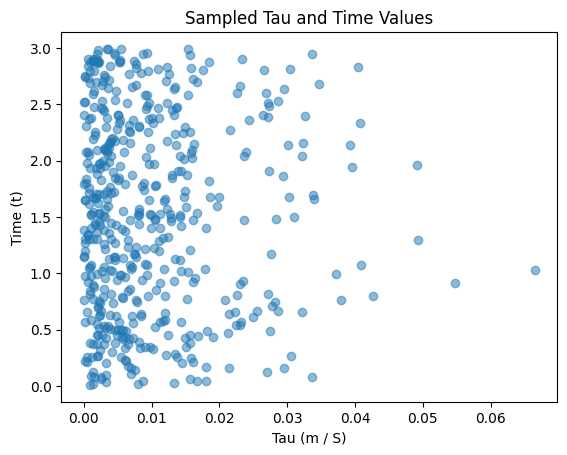

In [ ]:
# Define domain boundaries
lb = np.array([0., 0.])  # [min_tau, min_time]
ub = np.array([1., T])   # [max_tau, max_time]

# Instantiate Sampler_IBC
sampler = Sampler_IBC(lb, ub, N_points=1000, N_mc=100, DTYPE='float64')

# Sample (tau, t) pairs
samples = sampler.sample(method='uniform', N_time_points=500)

# Visualize sampled data
import matplotlib.pyplot as plt
plt.scatter(samples[:, 0], samples[:, 1], alpha=0.5)
plt.xlabel("Tau (m / S)")
plt.ylabel("Time (t)")
plt.title("Sampled Tau and Time Values")
plt.show()


In [ ]:
class Sampler_IBC():
    def __init__(self, lb, ub, N_points=100, N_mc=100, DTYPE='float64'):
        """
        lb: Lower bound of domain (e.g., [min_tau, min_time])
        ub: Upper bound of domain (e.g., [max_tau, max_time])
        N_points: Number of randomly sampled S values
        N_mc: Number of Monte Carlo iterations for m calculation
        DTYPE: Numerical precision
        """
        self.lb = lb
        self.ub = ub
        self.N_points = N_points
        self.N_mc = N_mc
        self.DTYPE = DTYPE

    def sample(self, method='uniform', N_time_points=100):
        """
        Sample tau and t values using different methods.
        method: Sampling method for S and time
        N_time_points: Number of time points to sample
        """
        if method == 'uniform':
            # Step 1: Sample S uniformly
            S_values = np.random.uniform(self.lb[0], self.ub[0], size=(self.N_points, 1)).astype(self.DTYPE)

        elif method == 'latin':
            from pyDOE import lhs
            # Latin Hypercube sampling for S
            S_values = self.lb[0] + (self.ub[0] - self.lb[0]) * lhs(1, samples=self.N_points).astype(self.DTYPE)

        elif method == 'sobol':
            import sobol
            # Sobol sequence for S
            sobol_samples = sobol.sample(dimension=1, n_points=self.N_points)
            S_values = self.lb[0] + (self.ub[0] - self.lb[0]) * sobol_samples.astype(self.DTYPE)

        elif method == 'equi':
            # Equally spaced sampling for S
            S_values = np.linspace(self.lb[0], self.ub[0], self.N_points).reshape(-1, 1).astype(self.DTYPE)

        else:
            raise ValueError(f"Unsupported sampling method: {method}")

        # Step 2: Calculate m using Monte Carlo
        m_values = []
        for S in S_values:
            mc_samples = np.random.uniform(0, S, size=self.N_mc).astype(self.DTYPE)
            m_mc = np.min(mc_samples)
            m_values.append(m_mc)
        m_values = np.array(m_values).reshape(-1, 1)

        # Step 3: Calculate tau = m / S
        tau_values = m_values / S_values

        # Step 4: Sample time t uniformly
        t_values = np.random.uniform(self.lb[1], self.ub[1], size=N_time_points).astype(self.DTYPE)

        # Step 5: Combine tau and t
        tau_values = np.random.choice(tau_values.flatten(), size=N_time_points, replace=False)
        samples = np.vstack([tau_values, t_values]).T  # Shape: (N_time_points, 2)

        return samples


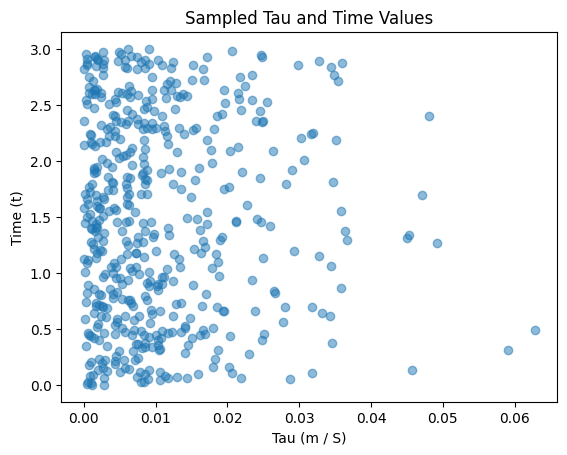

In [ ]:
# Define domain boundaries
lb = np.array([0., 0.])  # [min_tau, min_time]
ub = np.array([1., T])   # [max_tau, max_time]

# Instantiate Sampler_IBC
sampler = Sampler_IBC(lb, ub, N_points=1000, N_mc=100, DTYPE='float64')

# Use 'uniform' sampling method
samples = sampler.sample(method='uniform', N_time_points=500)

# Visualize sampled tau and time values
import matplotlib.pyplot as plt
plt.scatter(samples[:, 0], samples[:, 1], alpha=0.5)
plt.xlabel("Tau (m / S)")
plt.ylabel("Time (t)")
plt.title("Sampled Tau and Time Values")
plt.show()
